<a href="https://colab.research.google.com/github/Prativa239-pd/PRATIVA_RECENT/blob/main/Odisha_GEE_Satellite_Extraction_CORRECTED_VERSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Image Extraction for Odisha using Google Earth Engine

This notebook covers:
1. Setup and authentication
2. Odisha boundary (state + districts)
3. Sentinel-2 optical composite (cloud-masked) + spectral indices
4. Sentinel-1 SAR composite (works through monsoon clouds)
5. Landsat 8/9 composite (optional)
6. Interactive map
7. Export GeoTIFFs to Google Drive (state-wide or district-wise)
8. Monthly NDVI time series per district (to CSV and plot)
9. Reading the exported GeoTIFFs back in Colab



## 1. Install and import

In [1]:
!pip install -q geemap geedim rasterio

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 75.0 MB/s eta 0:00:00


## 2. Authenticate and initialize
Replace `YOUR_PROJECT_ID` with your Google Cloud project ID.

In [3]:
PROJECT_ID = "my-project-50729-prativa"

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)

print("Earth Engine initialized")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine initialized


## 3. Configuration
Change the dates, cloud threshold, and resolution here.

In [4]:
START_DATE   = "2024-06-01"     # e.g. kharif season start
END_DATE     = "2024-11-30"     # e.g. kharif season end
MAX_CLOUD    = 30               # max scene cloud % for Sentinel-2
SCALE_S2     = 10               # metres
SCALE_L8     = 30
DRIVE_FOLDER = "GEE_Odisha"     # Google Drive folder for exports

## 4. Odisha boundary
Uses FAO GAUL **2025** (the 2015 version is deprecated). The state name may appear as "Odisha" or the older "Orissa", so both are matched.

In [5]:
states    = ee.FeatureCollection("FAO/GAUL/2025/level1")
districts = ee.FeatureCollection("FAO/GAUL/2025/level2")

# GAUL 2025 uses GAUL1_NAME / GAUL2_NAME. The state may be spelled "Odisha" or the older "Orissa".
ODISHA_NAMES = ["Odisha", "Orissa"]

odisha = states.filter(ee.Filter.inList("GAUL1_NAME", ODISHA_NAMES))
odisha_districts = districts.filter(ee.Filter.inList("GAUL1_NAME", ODISHA_NAMES))
aoi = odisha.geometry()

# Detect the district-name column automatically (so later cells work either way)
props = odisha_districts.first().propertyNames().getInfo()
DIST_COL = "GAUL2_NAME" if "GAUL2_NAME" in props else next(p for p in props if p.upper().endswith("2_NAME"))
print("District name column:", DIST_COL)

print("State features found:", odisha.size().getInfo())
print("Districts found:", odisha_districts.size().getInfo())
print(sorted(odisha_districts.aggregate_array(DIST_COL).getInfo()))

District name column: GAUL2_NAME
State features found: 1
Districts found: 30
['Anugul', 'Balasore (Baleshwar)', 'Baragarh', 'Baudh (Bauda)', 'Bhadrak', 'Bolangir (Balangir)', 'Cuttack', 'Deogarh', 'Dhenkanal', 'Gajapati', 'Ganjam', 'Jagatsinghpur', 'Jajapur', 'Jharsuguda', 'Kalahandi', 'Kandhamal', 'Kendraparha', 'Keonjhar (Kendujhar)', 'Khordha', 'Koraput', 'Malkangiri', 'Mayurbhanj', 'Nabarangapur', 'Nayagarh', 'Nuaparha', 'Puri', 'Rayagarha', 'Sambalpur', 'Subarnapur', 'Sundargarh']


## 5. Sentinel-2 surface reflectance composite
Uses `COPERNICUS/S2_SR_HARMONIZED`, masks clouds and shadows with the Scene Classification Layer (SCL), then takes the median.

In [6]:
def mask_s2(img):
    scl = img.select("SCL")
    # keep: vegetation(4), bare soil(5), water(6), unclassified(7), snow(11 excluded)
    good = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7))
    return (img.updateMask(good)
               .divide(10000)
               .copyProperties(img, ["system:time_start"]))

def add_indices(img):
    ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")
    ndwi = img.normalizedDifference(["B3", "B8"]).rename("NDWI")      # water (McFeeters)
    mndwi = img.normalizedDifference(["B3", "B11"]).rename("MNDWI")
    ndbi = img.normalizedDifference(["B11", "B8"]).rename("NDBI")     # built-up
    evi = img.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {"NIR": img.select("B8"), "RED": img.select("B4"), "BLUE": img.select("B2")}
    ).rename("EVI")
    lswi = img.normalizedDifference(["B8", "B11"]).rename("LSWI")     # useful for paddy/flooding
    return img.addBands([ndvi, ndwi, mndwi, ndbi, evi, lswi])

s2_col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
          .filterBounds(aoi)
          .filterDate(START_DATE, END_DATE)
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD))
          .map(mask_s2)
          .map(add_indices))

print("Sentinel-2 scenes:", s2_col.size().getInfo())

s2_bands = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
idx_bands = ["NDVI", "NDWI", "MNDWI", "NDBI", "EVI", "LSWI"]

s2_median = s2_col.median().clip(aoi)
s2_stack = s2_median.select(s2_bands + idx_bands)
print(s2_stack.bandNames().getInfo())

Sentinel-2 scenes: 488
['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'EVI', 'LSWI']


## 6. Sentinel-1 SAR composite (VV, VH)
Radar sees through clouds, which is valuable in the Odisha monsoon.

In [7]:
s1_col = (ee.ImageCollection("COPERNICUS/S1_GRD")
          .filterBounds(aoi)
          .filterDate(START_DATE, END_DATE)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
          .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
          .select(["VV", "VH"]))

print("Sentinel-1 scenes:", s1_col.size().getInfo())

s1_median = s1_col.median().clip(aoi)
s1_ratio = s1_median.select("VV").subtract(s1_median.select("VH")).rename("VV_minus_VH")  # dB ratio
s1_stack = s1_median.addBands(s1_ratio)

Sentinel-1 scenes: 163


## 7. Landsat 8/9 composite (optional)

In [8]:
def prep_landsat(img):
    qa = img.select("QA_PIXEL")
    mask = (qa.bitwiseAnd(1 << 3).eq(0)      # cloud
            .And(qa.bitwiseAnd(1 << 4).eq(0))  # cloud shadow
            .And(qa.bitwiseAnd(1 << 5).eq(0))) # snow
    optical = img.select("SR_B.").multiply(0.0000275).add(-0.2)
    return (img.addBands(optical, None, True).updateMask(mask)
               .copyProperties(img, ["system:time_start"]))

l8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
l9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")

landsat_col = (l8.merge(l9)
               .filterBounds(aoi)
               .filterDate(START_DATE, END_DATE)
               .filter(ee.Filter.lt("CLOUD_COVER", 40))
               .map(prep_landsat))

landsat_median = (landsat_col.median()
                  .select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"],
                          ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"])
                  .clip(aoi))
print("Landsat scenes:", landsat_col.size().getInfo())

Landsat scenes: 143


## 8. Interactive map

In [10]:
Map = geemap.Map(center=[20.5, 84.5], zoom=7)

# Remove the default OpenStreetMap layer (blocked) and use a different basemap
for lyr in list(Map.layers):
    if "OpenStreetMap" in getattr(lyr, "name", ""):
        Map.remove(lyr)

try:
    Map.add_basemap("Esri.WorldImagery")
except Exception:
    Map.add_basemap("HYBRID")   # Google satellite fallback

Map.addLayer(s2_median, {"bands": ["B4", "B3", "B2"], "min": 0.0, "max": 0.3}, "Sentinel-2 RGB")
Map.addLayer(s2_median.select("NDVI"),
             {"min": 0, "max": 0.9, "palette": ["white", "yellow", "green", "darkgreen"]}, "NDVI")
Map.addLayer(s2_median.select("MNDWI"),
             {"min": -0.5, "max": 0.8, "palette": ["white", "lightblue", "blue"]}, "MNDWI (water)", False)
Map.addLayer(s1_median, {"bands": ["VV", "VH", "VV"], "min": [-20, -25, -20], "max": [0, -5, 0]},
             "Sentinel-1 VV/VH", False)
Map.addLayer(landsat_median, {"bands": ["Red", "Green", "Blue"], "min": 0.0, "max": 0.3},
             "Landsat RGB", False)
Map.addLayer(odisha_districts.style(color="black", fillColor="00000000", width=1), {}, "Districts")
Map.addLayerControl()
Map

Map(center=[20.5, 84.5], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

## 9. Export to Google Drive

Odisha is ~155,700 km2. At 10 m that is over 1.5 billion pixels per band, so a single state-wide export will usually hit limits. Two options:

- **Option A:** one state-wide export at coarser scale (e.g. 100 m) for a quick look
- **Option B (recommended):** export district by district at 10 m

In [11]:
# ---------- Option A: state-wide, coarse ----------
task = ee.batch.Export.image.toDrive(
    image=s2_stack.toFloat(),
    description="Odisha_S2_stack_100m",
    folder=DRIVE_FOLDER,
    fileNamePrefix="Odisha_S2_stack_100m",
    region=aoi,
    scale=100,
    crs="EPSG:32645",          # UTM zone 45N; Odisha spans 44N/45N, 45N is a fine single choice
    maxPixels=1e13
)
task.start()
print("Started state-wide export:", task.id)

Started state-wide export: V7TMEZX7I37UVEVF4OKQYS4C


In [12]:
# ---------- Option B: district-wise at 10 m ----------
def export_district(name, image, scale=10, prefix="S2"):
    geom = odisha_districts.filter(ee.Filter.eq(DIST_COL, name)).geometry()
    safe = name.replace(" ", "_")
    t = ee.batch.Export.image.toDrive(
        image=image.clip(geom).toFloat(),
        description=f"{prefix}_{safe}",
        folder=DRIVE_FOLDER,
        fileNamePrefix=f"{prefix}_{safe}",
        region=geom,
        scale=scale,
        crs="EPSG:32645",
        maxPixels=1e13
    )
    t.start()
    return t

district_names = sorted(odisha_districts.aggregate_array(DIST_COL).getInfo())

# Start with a few districts to test; set to district_names for all
selected = ["Khordha", "Cuttack", "Puri"]

tasks = [export_district(d, s2_stack, scale=SCALE_S2, prefix="S2") for d in selected]
print(f"Started {len(tasks)} exports. Track at https://code.earthengine.google.com/tasks")

Started 3 exports. Track at https://code.earthengine.google.com/tasks


In [13]:
# Export Sentinel-1 the same way (optional)
s1_tasks = [export_district(d, s1_stack, scale=10, prefix="S1") for d in selected]

In [14]:
# Check task status
for t in tasks + s1_tasks:
    print(t.status()["description"], "->", t.status()["state"])

S2_Khordha -> READY
S2_Cuttack -> READY
S2_Puri -> READY
S1_Khordha -> READY
S1_Cuttack -> READY
S1_Puri -> READY


## 10. Monthly NDVI time series per district

In [15]:
# Monthly median NDVI, mean over each district
months = ee.List.sequence(1, 12)
year = 2024

def monthly_ndvi(m):
    m = ee.Number(m)
    start = ee.Date.fromYMD(year, m, 1)
    end = start.advance(1, "month")
    img = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(aoi).filterDate(start, end)
           .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60))
           .map(mask_s2)
           .map(lambda i: i.normalizedDifference(["B8", "B4"]).rename("NDVI"))
           .median())
    stats = img.reduceRegions(
        collection=odisha_districts.filter(ee.Filter.inList(DIST_COL, selected)),
        reducer=ee.Reducer.mean(),
        scale=100
    ).map(lambda f: f.set("month", m).set("year", year))
    return stats

ts_fc = ee.FeatureCollection(months.map(monthly_ndvi)).flatten()
ts_df = geemap.ee_to_df(ts_fc, columns=[DIST_COL, "year", "month", "mean"])
ts_df = ts_df.rename(columns={"mean": "NDVI", DIST_COL: "District"})
ts_df.to_csv("odisha_monthly_ndvi.csv", index=False)
ts_df.head()

,District,year,month,NDVI
0,Khordha,2024,1,0.361244
1,Puri,2024,1,0.225528
2,Cuttack,2024,1,0.362636
3,Khordha,2024,2,0.412665
4,Puri,2024,2,0.295359


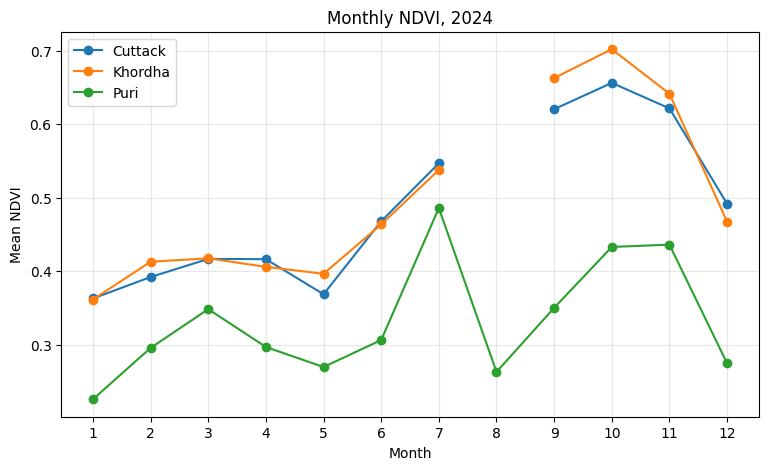

In [16]:
plt.figure(figsize=(9, 5))
for d, g in ts_df.groupby("District"):
    g = g.sort_values("month")
    plt.plot(g["month"], g["NDVI"], marker="o", label=d)
plt.xlabel("Month"); plt.ylabel("Mean NDVI"); plt.title(f"Monthly NDVI, {year}")
plt.xticks(range(1, 13)); plt.grid(alpha=0.3); plt.legend()
plt.show()

## 11. Quick download of a small area (no Drive needed)
Direct download only works for small areas (about 50 MB limit). Good for testing.

In [18]:
import requests, rasterio, numpy as np
from rasterio.merge import merge

# Same area as before
xmin, ymin, xmax, ymax = 85.75, 20.20, 85.95, 20.40
small_roi = ee.Geometry.Rectangle([xmin, ymin, xmax, ymax])

img = s2_median.select(["B4", "B3", "B2", "B8", "NDVI"]).toFloat()

N = 3  # N x N tiles (3x3 = 9 tiles, ~14 MB each). Use a bigger N for a bigger area.
xs = np.linspace(xmin, xmax, N + 1)
ys = np.linspace(ymin, ymax, N + 1)

tile_files = []
for i in range(N):
    for j in range(N):
        tile = ee.Geometry.Rectangle([float(xs[i]), float(ys[j]), float(xs[i+1]), float(ys[j+1])])
        url = img.getDownloadURL({
            "region": tile,
            "scale": 10,
            "crs": "EPSG:4326",
            "format": "GEO_TIFF",
        })
        r = requests.get(url)
        r.raise_for_status()
        fn = f"tile_{i}_{j}.tif"
        with open(fn, "wb") as f:
            f.write(r.content)
        tile_files.append(fn)
        print("Downloaded", fn, round(len(r.content) / 1e6, 1), "MB")

# Merge tiles into one GeoTIFF
srcs = [rasterio.open(f) for f in tile_files]
mosaic, transform = merge(srcs)
meta = srcs[0].meta.copy()
meta.update({"height": mosaic.shape[1], "width": mosaic.shape[2], "transform": transform})
for s in srcs:
    s.close()

with rasterio.open("bhubaneswar_s2.tif", "w", **meta) as dst:
    dst.write(mosaic)

print("Saved bhubaneswar_s2.tif", mosaic.shape)

Downloaded tile_0_0.tif 7.0 MB
Downloaded tile_0_1.tif 7.0 MB
Downloaded tile_0_2.tif 6.9 MB
Downloaded tile_1_0.tif 7.1 MB
Downloaded tile_1_1.tif 7.1 MB
Downloaded tile_1_2.tif 7.0 MB
Downloaded tile_2_0.tif 6.9 MB
Downloaded tile_2_1.tif 7.0 MB


Downloaded tile_2_2.tif 7.0 MB
Saved bhubaneswar_s2.tif (5, 2227, 2228)


## 12. Read exported GeoTIFFs in Colab

In [19]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Shape: (2227, 2228) | Bands: 5 | CRS: EPSG:4326
(None, None, None, None, None)


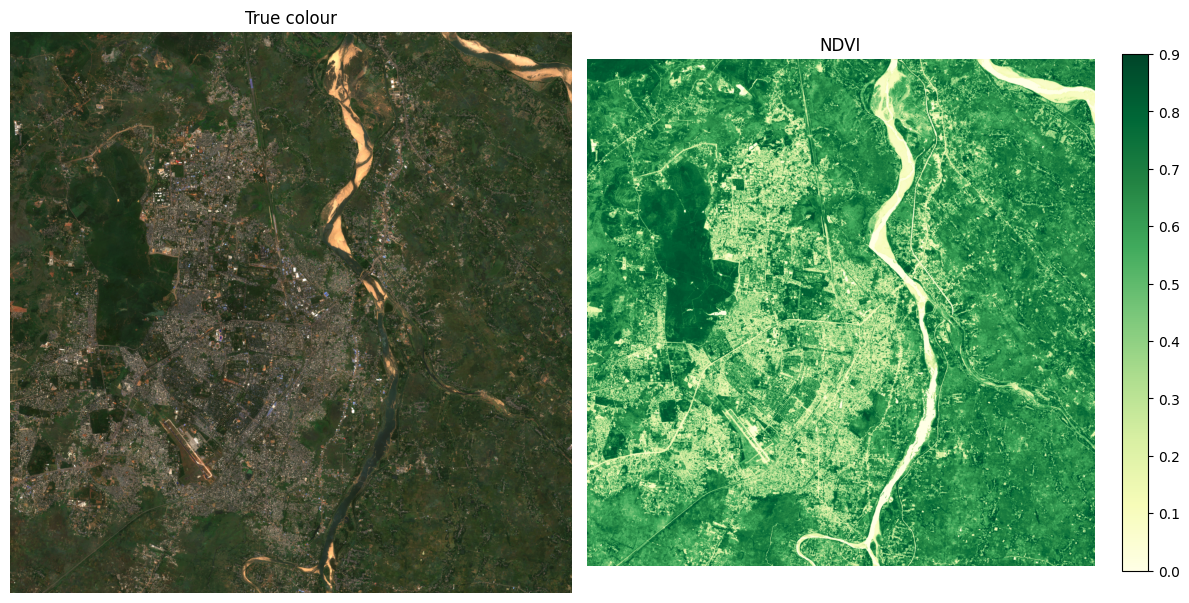

In [20]:
import rasterio

# Use the quick-download file, or point to a Drive export:
# path = "/content/drive/MyDrive/GEE_Odisha/S2_Khordha.tif"
path = "bhubaneswar_s2.tif"

with rasterio.open(path) as src:
    print("Shape:", src.shape, "| Bands:", src.count, "| CRS:", src.crs)
    arr = src.read().astype("float32")
    names = src.descriptions
print(names)

rgb = np.stack([arr[0], arr[1], arr[2]], axis=-1)
rgb = np.clip(rgb / 0.3, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(rgb); ax[0].set_title("True colour"); ax[0].axis("off")
im = ax[1].imshow(arr[4], cmap="YlGn", vmin=0, vmax=0.9); ax[1].set_title("NDVI"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()